## ۱. آماده‌سازی محیط و بارگذاری داده‌ها


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the dataset
df_raw = pd.read_csv("StudentsPerformance.csv")
df = df_raw.copy()

# Display dataset information
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Rows: 1,000 | Columns: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## ۲. قبل از تحلیل، دقیقاً چه داده‌ای داریم؟

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nDtypes and non-null counts:")
df.info()

Shape: (1000, 8)

Columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dtypes and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


### سؤال اول: آیا داده برای تحلیل آماده است؟

In [5]:
score_columns = ["math score", "reading score", "writing score"]
categorical_columns = [
    "gender", "race/ethnicity", "parental level of education",
    "lunch", "test preparation course"
]

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})

quality_summary = pd.Series({
    "rows": len(df),
    "columns": df.shape[1],
    "missing_cells": int(df.isna().sum().sum()),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "rows_with_any_score_below_0": int((df[score_columns] < 0).any(axis=1).sum()),
    "rows_with_any_score_above_100": int((df[score_columns] > 100).any(axis=1).sum()),
})

display(quality_summary.to_frame("value"))
display(missing_report)

score_validation = pd.DataFrame({
    "min": df[score_columns].min(),
    "max": df[score_columns].max(),
    "non_numeric": [int(pd.to_numeric(df[c], errors="coerce").isna().sum()) for c in score_columns],
    "below_0": (df[score_columns] < 0).sum(),
    "above_100": (df[score_columns] > 100).sum(),
})
display(score_validation)

,value
rows,1000
columns,8
missing_cells,0
exact_duplicate_rows,0
rows_with_any_score_below_0,0
rows_with_any_score_above_100,0


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


,min,max,non_numeric,below_0,above_100
math score,0,100,0,0,0
reading score,17,100,0,0,0
writing score,10,100,0,0,0


**تفسیر روش‌شناختی:** بررسی اولیه‌ی نوت‌بوک قبلی‌ات نشان می‌داد هیچ مقدار خالی و هیچ ردیف کاملاً تکراری‌ای وجود ندارد و نمره‌ها خارج از بازه‌ی ۰ تا ۱۰۰ نیستند. این نکته مهم است: اگر همین بررسی در اجرای فعلی نیز تأیید شود، نیازی به پرکردن داده‌ی گمشده یا حذف ردیف نداریم. نمره‌ی صفر ریاضی که در بررسی قبلی دیده می‌شد، ارزش بازبینی دارد؛ اما بدون شواهد بیشتر نباید خودکار آن را به مقدار گمشده تبدیل کرد.

## ۳. آماده‌سازی و تبدیل داده‌ها

In [6]:
education_order = [
    "some high school", "high school", "some college",
    "associate's degree", "bachelor's degree", "master's degree"
]
gender_order = ["female", "male"]
lunch_order = ["free/reduced", "standard"]
prep_order = ["none", "completed"]
race_order = ["group A", "group B", "group C", "group D", "group E"]

# نسخه‌ی تحلیل را از داده‌ی خام جدا نگه می‌داریم.
df = df_raw.copy()

df["overall_average"] = df[score_columns].mean(axis=1)
df["literacy_average"] = df[["reading score", "writing score"]].mean(axis=1)
df["math_minus_literacy"] = df["math score"] - df["literacy_average"]
df["reading_minus_writing"] = df["reading score"] - df["writing score"]
df["within_student_score_range"] = df[score_columns].max(axis=1) - df[score_columns].min(axis=1)

df["performance_quartile"] = pd.qcut(
    df["overall_average"], q=4,
    labels=["Q1 - lowest", "Q2", "Q3", "Q4 - highest"],
    duplicates="drop"
)

score_long = df.melt(
    id_vars=categorical_columns + ["overall_average", "literacy_average"],
    value_vars=score_columns,
    var_name="subject",
    value_name="score"
)
subject_labels = {
    "math score": "Math",
    "reading score": "Reading",
    "writing score": "Writing",
}
score_long["subject"] = score_long["subject"].map(subject_labels)
score_long["subject"] = pd.Categorical(score_long["subject"], categories=["Math", "Reading", "Writing"], ordered=True)

print("Long-form shape:", score_long.shape)
display(df[[*score_columns, "overall_average", "literacy_average", "math_minus_literacy", "within_student_score_range"]].head())

Long-form shape: (3000, 9)


,math score,reading score,writing score,overall_average,literacy_average,math_minus_literacy,within_student_score_range
0,72,72,74,72.666667,73.0,-1.0,2
1,69,90,88,82.333333,89.0,-20.0,21
2,90,95,93,92.666667,94.0,-4.0,5
3,47,57,44,49.333333,50.5,-3.5,13
4,76,78,75,76.333333,76.5,-0.5,3


## ۴. آمار توصیفی

In [7]:
summary = df[score_columns].agg(["count", "mean", "median", "std", "var", "min", "max"]).T
summary["range"] = df[score_columns].max() - df[score_columns].min()
summary["Q1"] = df[score_columns].quantile(0.25)
summary["Q3"] = df[score_columns].quantile(0.75)
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary["skewness"] = df[score_columns].skew()
summary["mode"] = [df[col].mode().tolist() for col in score_columns]
display(summary.round(2))

,count,mean,median,std,var,min,max,range,Q1,Q3,IQR,skewness,mode
math score,1000.0,66.09,66.0,15.16,229.92,0.0,100.0,100,57.00,77.0,20.00,-0.28,[65]
reading score,1000.0,69.17,70.0,14.60,213.17,17.0,100.0,83,59.00,79.0,20.00,-0.26,[72]
writing score,1000.0,68.05,69.0,15.20,230.91,10.0,100.0,90,57.75,79.0,21.25,-0.29,[74]



در خروجی ثبت‌شده‌ی نسخه‌ی قبلی، میانگین ریاضی **۶۶٫۰۹**، خواندن **۶۹٫۱۷** و نوشتن **۶۸٫۰۵** بود؛ میانه‌ها نیز به‌ترتیب **۶۶، ۷۰ و ۶۹** بودند. نزدیک بودن میانگین و میانه نشان می‌دهد مرکز توزیع‌ها در این سه درس خیلی از هم دور نیست؛ با این حال، شکل دقیق توزیع و دنباله‌های آن را باید با نمودارها بررسی کرد. ریاضی کمینه‌ی صفر داشت، در حالی‌ که کمینه‌ی خواندن ۱۷ و نوشتن ۱۰ بود؛ این تفاوت ارزش بررسی جداگانه دارد.

## ۵. توزیع هر درس: histogram، boxplot و violin plot

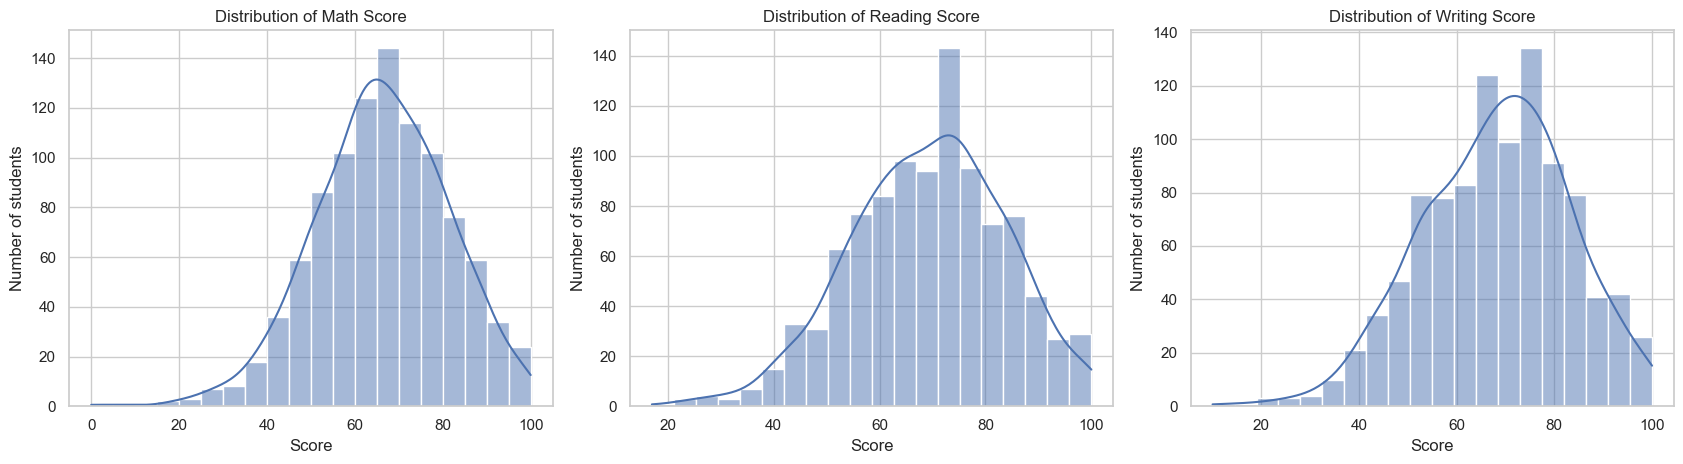

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col in zip(axes, score_columns):
    sns.histplot(data=df, x=col, bins=20, kde=True, color="#4C72B0", ax=ax)
    ax.set_title(f"Distribution of {col.title()}")
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()

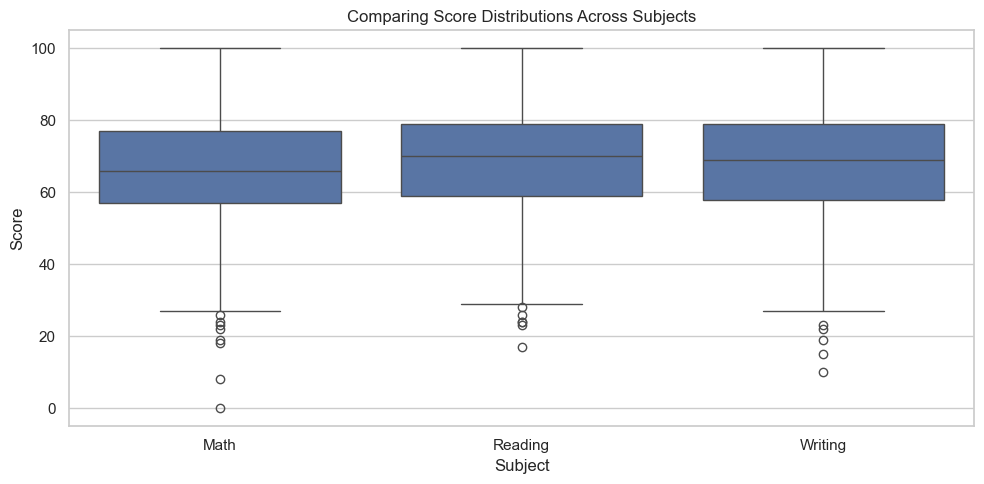

In [9]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=score_long, x="subject", y="score", order=["Math", "Reading", "Writing"], color="#4C72B0")
plt.title("Comparing Score Distributions Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

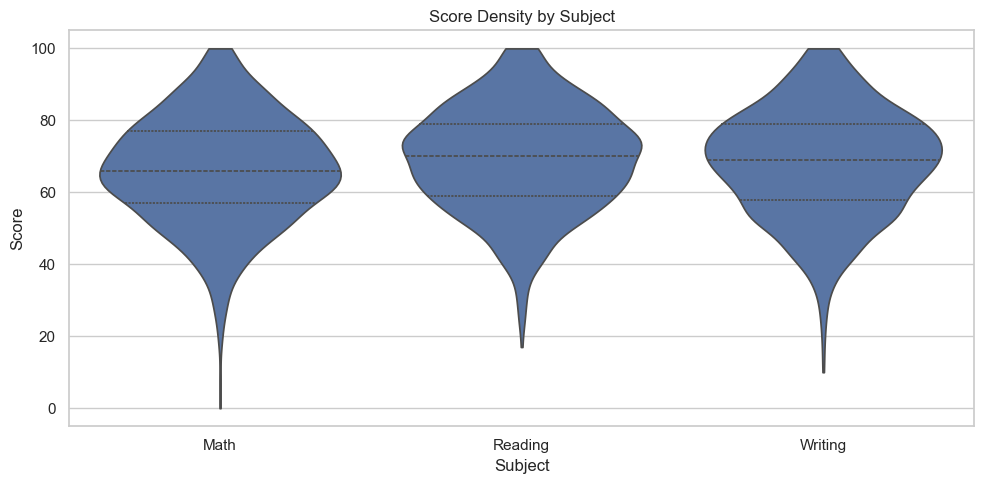

In [10]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=score_long, x="subject", y="score", order=["Math", "Reading", "Writing"], inner="quartile", cut=0, color="#4C72B0")
plt.title("Score Density by Subject")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

### نقاط دورافتاده را حذف کنیم؟ نه، اول بفهمیم چه هستند.

In [11]:
outlier_rows = []
for col in score_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "subject": col,
        "lower_IQR_fence": lower,
        "upper_IQR_fence": upper,
        "potential_outliers": int(mask.sum()),
        "below_fence": int((df[col] < lower).sum()),
        "above_fence": int((df[col] > upper).sum()),
    })
display(pd.DataFrame(outlier_rows).round(2))

# بررسی رکوردهای غیرمعمول، به‌ویژه نمره‌ی صفر؛ این ردیف‌ها را خودکار حذف نمی‌کنیم.
zero_score_rows = df.loc[(df[score_columns] == 0).any(axis=1), categorical_columns + score_columns]
print("Rows containing at least one zero score:", len(zero_score_rows))
display(zero_score_rows)

,subject,lower_IQR_fence,upper_IQR_fence,potential_outliers,below_fence,above_fence
0,math score,27.00,107.00,8,8,0
1,reading score,29.00,109.00,6,6,0
2,writing score,25.88,110.88,5,5,0


Rows containing at least one zero score: 1


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10


## ۶. ویژگی‌های دسته‌ای

In [12]:
category_tables = {}
for col in categorical_columns:
    counts = df[col].value_counts(dropna=False)
    table = pd.DataFrame({
        "count": counts,
        "percent": (counts / len(df) * 100).round(1)
    })
    category_tables[col] = table
    print(f"\n--- {col} ---")
    display(table)


--- gender ---


,count,percent
gender,,
female,518,51.8
male,482,48.2



--- race/ethnicity ---


,count,percent
race/ethnicity,,
group C,319,31.9
group D,262,26.2
group B,190,19.0
group E,140,14.0
group A,89,8.9



--- parental level of education ---


,count,percent
parental level of education,,
some college,226,22.6
associate's degree,222,22.2
high school,196,19.6
some high school,179,17.9
bachelor's degree,118,11.8
master's degree,59,5.9



--- lunch ---


,count,percent
lunch,,
standard,645,64.5
free/reduced,355,35.5



--- test preparation course ---


,count,percent
test preparation course,,
none,642,64.2
completed,358,35.8


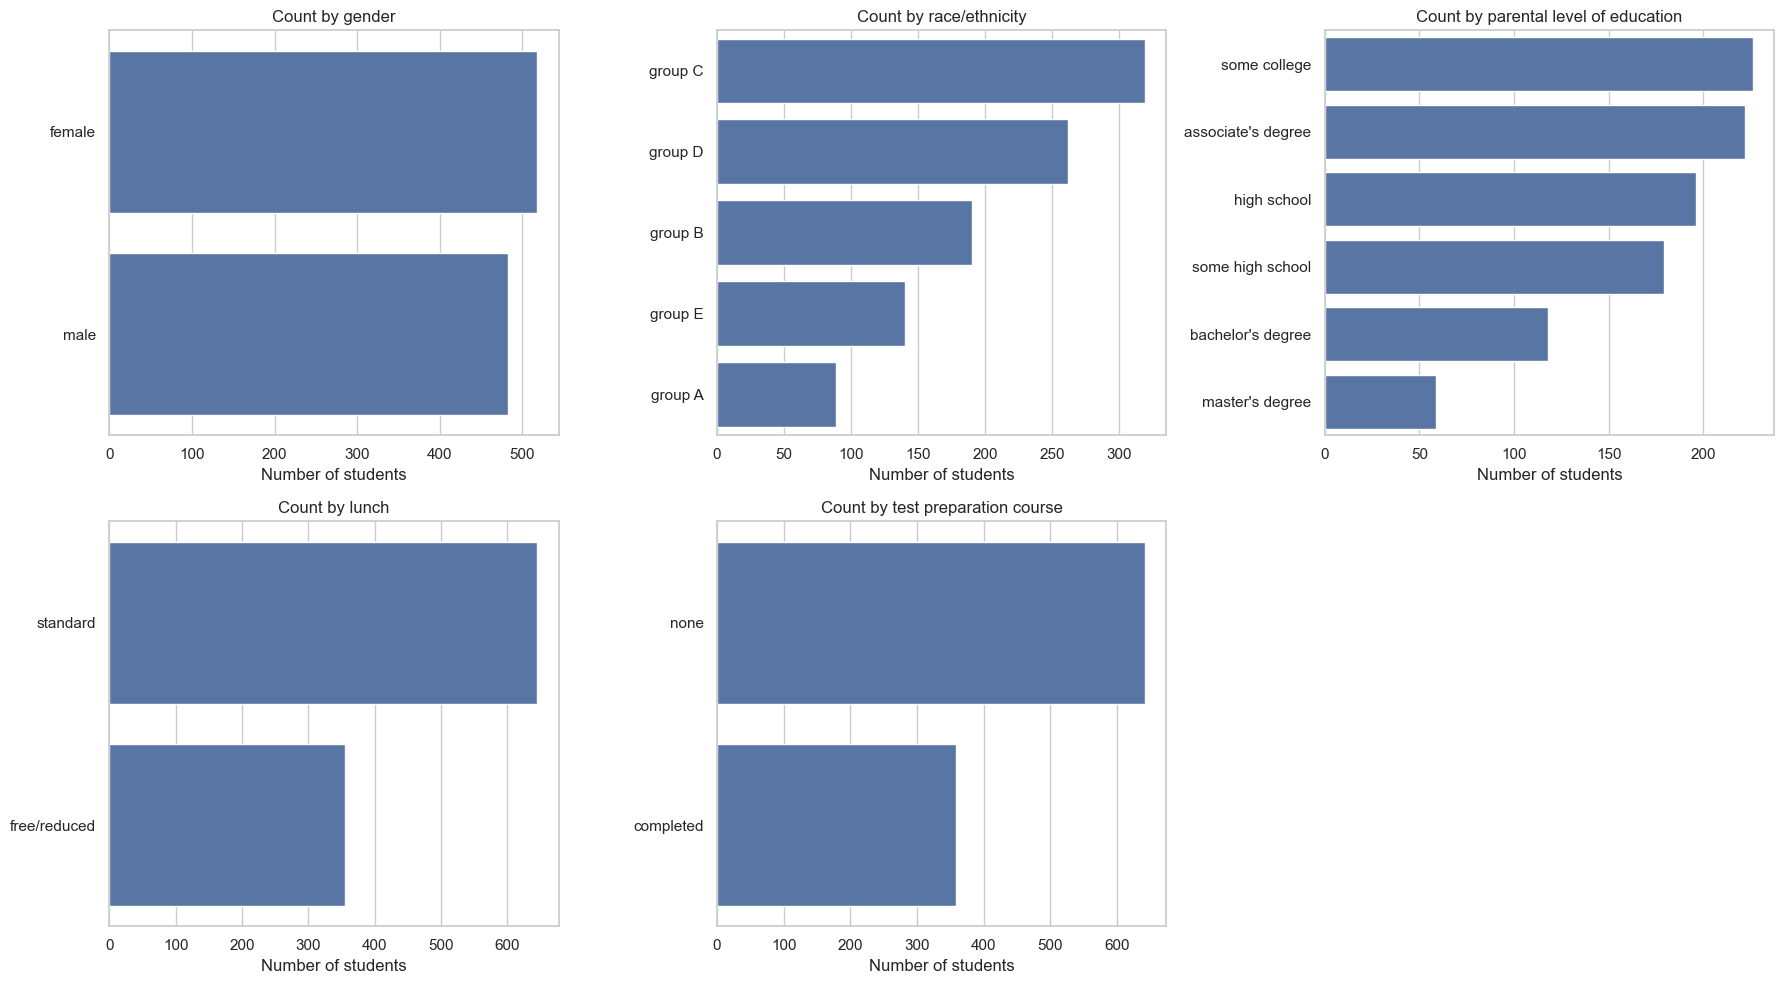

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, col in zip(axes, categorical_columns):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, color="#4C72B0", ax=ax)
    ax.set_title(f"Count by {col}")
    ax.set_xlabel("Number of students")
    ax.set_ylabel("")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

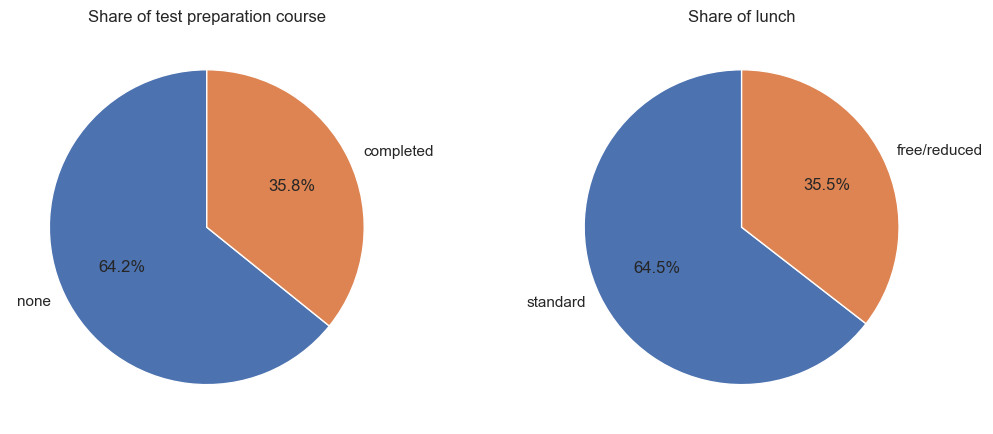

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["test preparation course", "lunch"]):
    counts = df[col].value_counts()
    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"Share of {col}")
plt.tight_layout()
plt.show()

## ۷. رابطه‌ی عملکرد با جنسیت: آیا الگو در همه‌ی درس‌ها یکسان است؟

math score                      reading score                      writing score                      overall_average         \
            count   mean median    std         count   mean median    std         count   mean median    std           count   mean   
gender                                                                                                                                
female        518  63.63   65.0  15.49           518  72.61   73.0  14.38           518  72.47   74.0  14.84             518  69.57   
male          482  68.73   69.0  14.36           482  65.47   66.0  13.93           482  63.31   64.0  14.11             482  65.84   

                     literacy_average                       
       median    std            count   mean median    std  
gender                                                      
female  70.33  14.54              518  72.54   73.0  14.45  
male    66.33  13.70              482  64.39   65.0  13.85

gender,female,male
Math,63.63,68.73
Reading,72.61,65.47
Writing,72.47,63.31


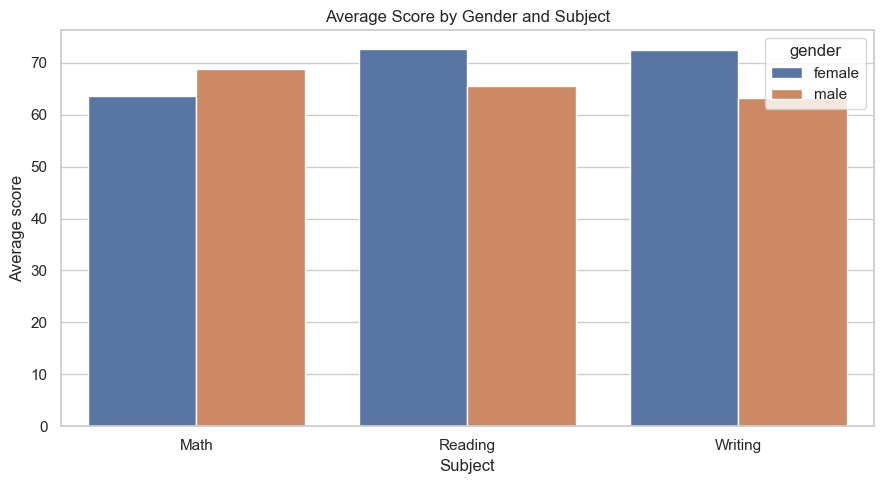

In [15]:
gender_summary = df.groupby("gender", observed=False)[score_columns + ["overall_average", "literacy_average"]].agg(["count", "mean", "median", "std"])
display(gender_summary.round(2))

gender_subject_means = df.groupby("gender", observed=False)[score_columns].mean().T
gender_subject_means.index = [subject_labels.get(index, index) for index in gender_subject_means.index]
display(gender_subject_means.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=score_long, x="subject", y="score", hue="gender", order=["Math", "Reading", "Writing"], errorbar=None)
plt.title("Average Score by Gender and Subject")
plt.xlabel("Subject")
plt.ylabel("Average score")
plt.tight_layout()
plt.show()


| درس | دخترها | پسرها | اختلاف توصیفی |
|---|---:|---:|---:|
| ریاضی | 63.63 | 68.73 | پسرها حدود 5.10 نمره بالاتر |
| خواندن | 72.61 | 65.47 | دخترها حدود 7.14 نمره بالاتر |
| نوشتن | 72.47 | 63.31 | دخترها حدود 9.16 نمره بالاتر |


## ۸. تحصیلات والدین


,mean | math score,mean | reading score,mean | writing score,mean | overall_average,median | math score,median | reading score,median | writing score,median | overall_average,n
parental level of education,,,,,,,,,
some high school,63.50,66.94,64.89,65.11,65.0,67.0,66.0,66.67,179
high school,62.14,64.70,62.45,63.10,63.0,66.0,64.0,65.00,196
some college,67.13,69.46,68.84,68.48,67.5,70.5,70.0,68.67,226
associate's degree,67.88,70.93,69.90,69.57,67.0,72.5,70.5,69.67,222
bachelor's degree,69.39,73.00,73.38,71.92,68.0,73.0,74.0,71.17,118
master's degree,69.75,75.37,75.68,73.60,73.0,76.0,75.0,73.33,59


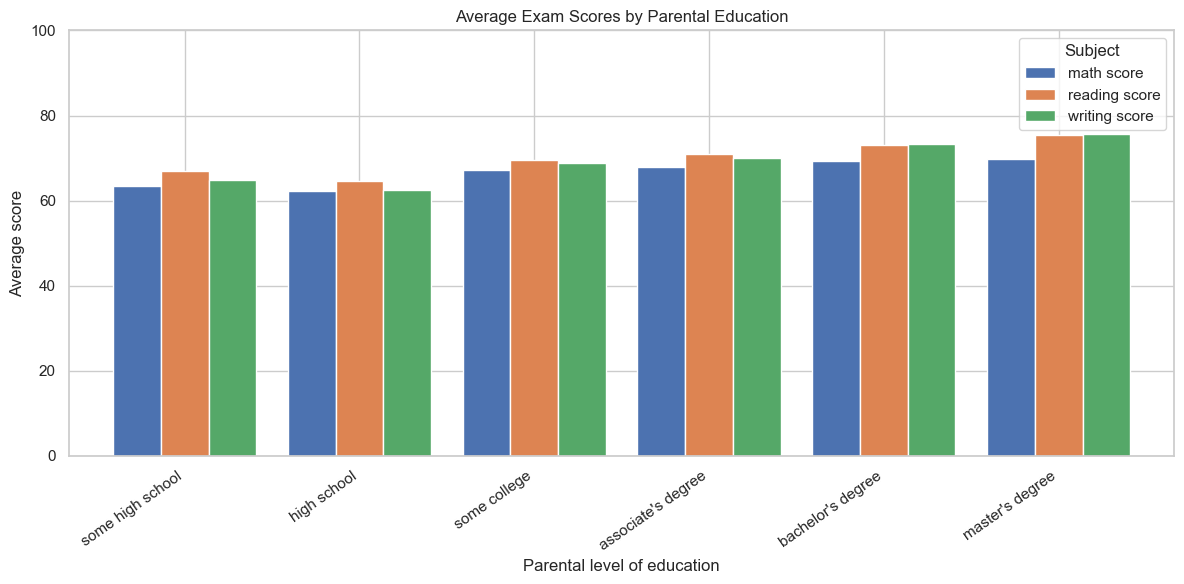

In [16]:
parent_counts = df["parental level of education"].value_counts().reindex(education_order)
parent_means = df.groupby("parental level of education", observed=False)[score_columns + ["overall_average"]].mean().reindex(education_order)
parent_medians = df.groupby("parental level of education", observed=False)[score_columns + ["overall_average"]].median().reindex(education_order)
parent_summary = parent_means.add_prefix("mean | ").join(parent_medians.add_prefix("median | ")).join(parent_counts.rename("n"))
display(parent_summary.round(2))

parent_means[score_columns].plot(kind="bar", figsize=(12, 6), width=0.82)
plt.title("Average Exam Scores by Parental Education")
plt.xlabel("Parental level of education")
plt.ylabel("Average score")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 100)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

## ۹.نوع ناهار


math score                      reading score                      writing score                      overall_average         \
                  count   mean median    std         count   mean median    std         count   mean median    std           count   mean   
lunch                                                                                                                                       
free/reduced        355  58.92   60.0  15.16           355  64.65   65.0  14.90           355  63.02   64.0  15.43             355  62.20   
standard            645  70.03   69.0  13.65           645  71.65   72.0  13.83           645  70.82   72.0  14.34             645  70.84   

                           literacy_average                       
             median    std            count   mean median    std  
lunch                                                             
free/reduced  62.67  14.46              355  63.84   64.0  15.00  
standard      71.33  13.19              645  71.24   72.0  13.91

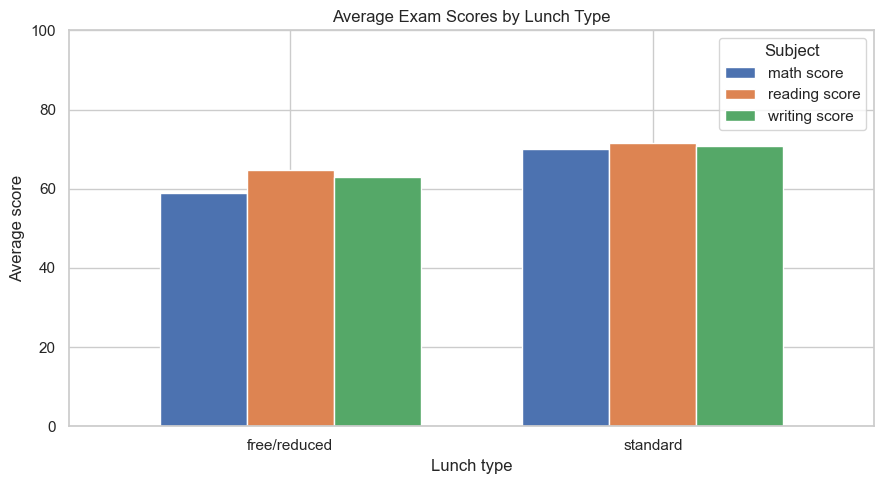

,standard minus free/reduced
math score,11.11
reading score,7.00
writing score,7.80


In [17]:
lunch_summary = df.groupby("lunch", observed=False)[score_columns + ["overall_average", "literacy_average"]].agg(["count", "mean", "median", "std"])
display(lunch_summary.round(2))

lunch_means = df.groupby("lunch", observed=False)[score_columns].mean().reindex(lunch_order)
ax = lunch_means.plot(kind="bar", figsize=(9, 5), width=0.72)
ax.set_title("Average Exam Scores by Lunch Type")
ax.set_xlabel("Lunch type")
ax.set_ylabel("Average score")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Subject")
plt.tight_layout()
plt.show()

lunch_difference = (lunch_means.loc["standard"] - lunch_means.loc["free/reduced"]).rename("standard minus free/reduced")
display(lunch_difference.round(2).to_frame())

## ۱۰. دوره‌ی آمادگی آزمون


math score                      reading score                      writing score                       \
                             count   mean median    std         count   mean median    std         count   mean median    std   
test preparation course                                                                                                         
completed                      358  69.70   69.0  14.44           358  73.89   75.0  13.64           358  74.42   76.0  13.38   
none                           642  64.08   64.0  15.19           642  66.53   67.0  14.46           642  64.50   65.0  15.00   

                        overall_average                      literacy_average                       
                                  count   mean median    std            count   mean median    std  
test preparation course                                                                             
completed                           358  72.67  73.50  13.04              358  74.16   75.5  13.33  
none                                642  65.04  65.33  14.19              642  65.52   66.0  14.57

,math score,reading score,writing score,overall_average
test preparation course,,,,
none,64.08,66.53,64.50,65.04
completed,69.70,73.89,74.42,72.67


,completed minus none
math score,5.62
reading score,7.36
writing score,9.91
overall_average,7.63


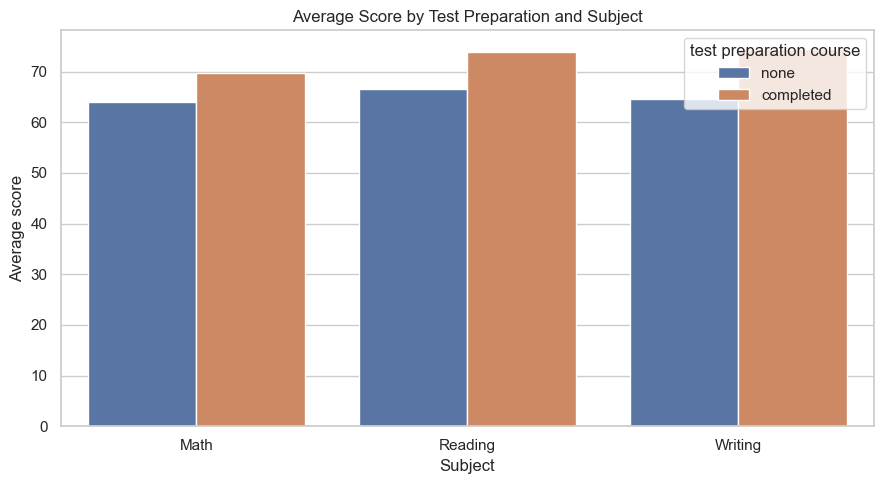

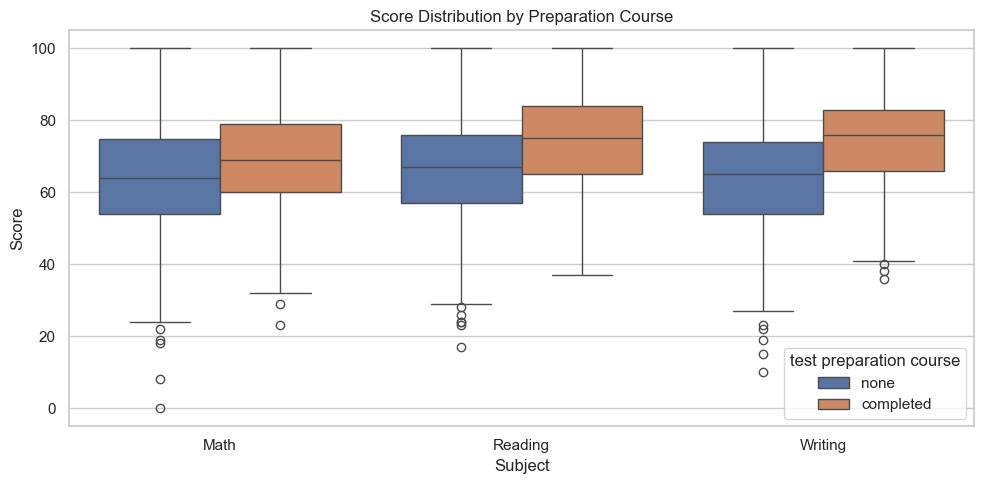

In [18]:
prep_summary = df.groupby("test preparation course", observed=False)[score_columns + ["overall_average", "literacy_average"]].agg(["count", "mean", "median", "std"])
display(prep_summary.round(2))

prep_means = df.groupby("test preparation course", observed=False)[score_columns + ["overall_average"]].mean().reindex(prep_order)
prep_difference = (prep_means.loc["completed"] - prep_means.loc["none"]).rename("completed minus none")
display(prep_means.round(2))
display(prep_difference.round(2).to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(data=score_long, x="subject", y="score", hue="test preparation course", order=["Math", "Reading", "Writing"], errorbar=None)
plt.title("Average Score by Test Preparation and Subject")
plt.xlabel("Subject")
plt.ylabel("Average score")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=score_long, x="subject", y="score", hue="test preparation course", order=["Math", "Reading", "Writing"])
plt.title("Score Distribution by Preparation Course")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## ۱۱. درس‌ها چقدر با هم حرکت می‌کنند؟


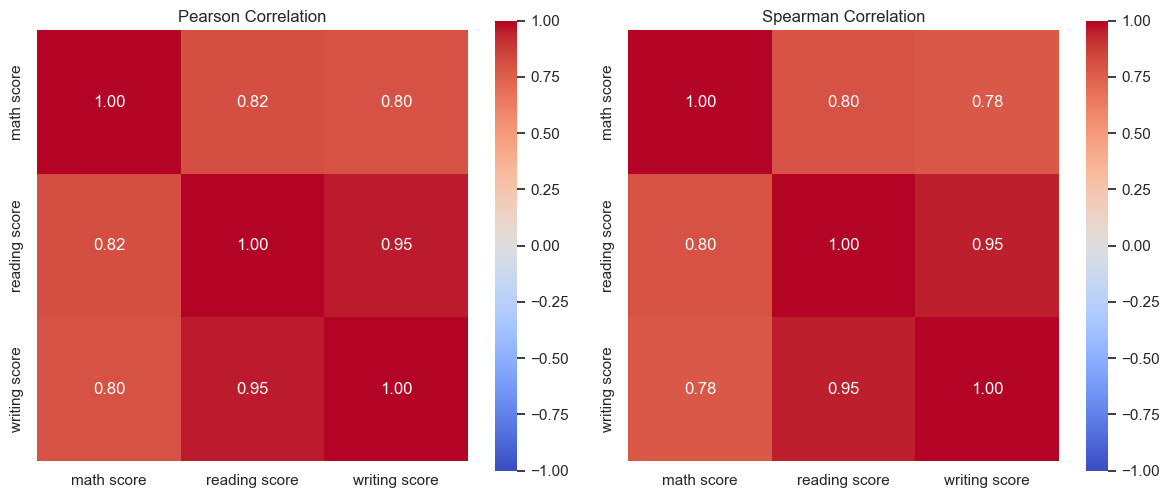

,math score,reading score,writing score
math score,1.000,0.818,0.803
reading score,0.818,1.000,0.955
writing score,0.803,0.955,1.000


,math score,reading score,writing score
math score,1.000,0.804,0.778
reading score,0.804,1.000,0.949
writing score,0.778,0.949,1.000


In [19]:
pearson_corr = df[score_columns].corr(method="pearson")
spearman_corr = df[score_columns].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0, fmt=".2f", square=True, ax=axes[0])
axes[0].set_title("Pearson Correlation")
sns.heatmap(spearman_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0, fmt=".2f", square=True, ax=axes[1])
axes[1].set_title("Spearman Correlation")
plt.tight_layout()
plt.show()

display(pearson_corr.round(3))
display(spearman_corr.round(3))

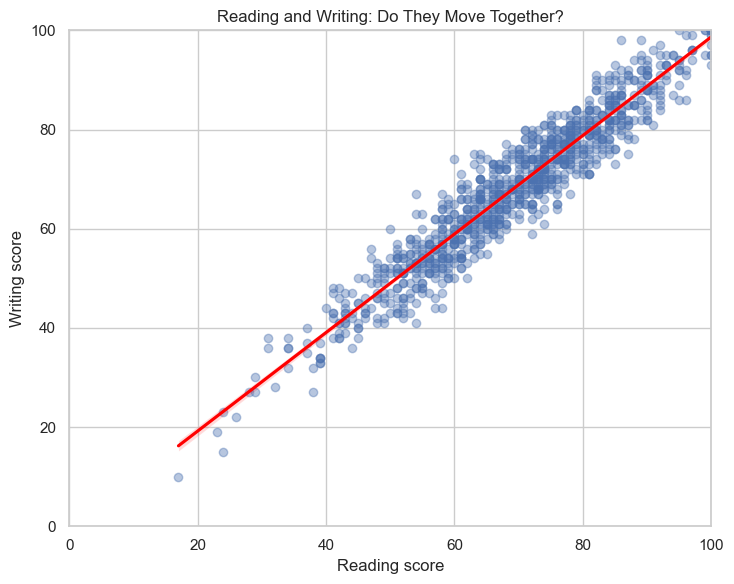

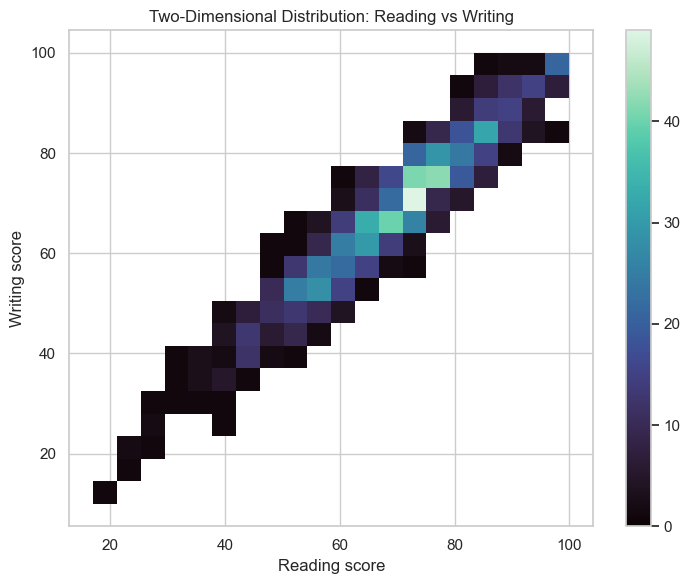

In [20]:
plt.figure(figsize=(7.5, 6))
sns.regplot(data=df, x="reading score", y="writing score", scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Reading and Writing: Do They Move Together?")
plt.xlabel("Reading score")
plt.ylabel("Writing score")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7.5, 6))
sns.histplot(data=df, x="reading score", y="writing score", bins=20, cbar=True, cmap="mako")
plt.title("Two-Dimensional Distribution: Reading vs Writing")
plt.xlabel("Reading score")
plt.ylabel("Writing score")
plt.tight_layout()
plt.show()

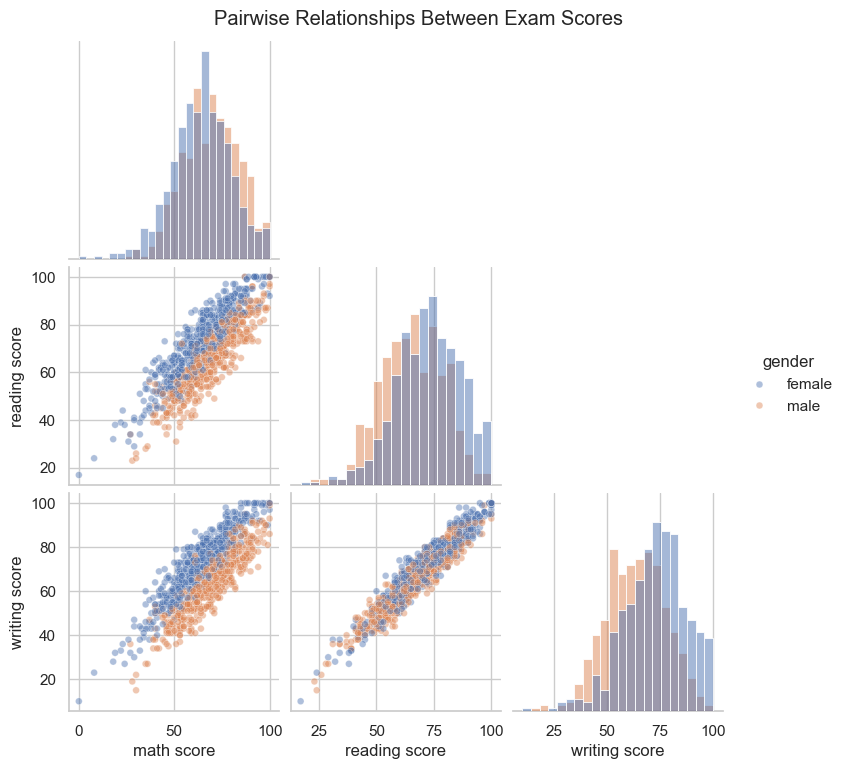

In [21]:
# Pairplot: scatter plots for each pair of subjects, with gender as a visual grouping.
sns.pairplot(
    df,
    vars=score_columns,
    hue="gender",
    corner=True,
    plot_kws={"alpha": 0.45, "s": 24},
    diag_kind="hist"
)
plt.suptitle("Pairwise Relationships Between Exam Scores", y=1.02)
plt.show()

در تحلیل ثبت‌شده‌ی اولیه، همبستگی خواندن و نوشتن **۰٫۹۵** بود؛ قوی‌تر از همبستگی ریاضی با خواندن (**۰٫۸۲**) و ریاضی با نوشتن (**۰٫۸۰**). روایت محتاطانه این است که عملکرد خواندن و نوشتن در این نمونه با هم بسیار هم‌راستا است؛ احتمالاً بخشی از مهارت‌های مشترک زبانی را بازتاب می‌دهند، اما این دیتاست آن سازوکار را مستقیماً اندازه‌گیری نمی‌کند.

## ۱۴. تفاوت‌های درون هر دانش‌آموز: آیا یک نمره نماینده‌ی کل عملکرد است؟


,overall_average,literacy_average,math_minus_literacy,reading_minus_writing,within_student_score_range
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,67.77,68.61,-2.52,1.12,9.79
std,14.26,14.73,8.99,4.53,5.29
min,9.00,13.50,-26.50,-14.00,0.00
25%,58.33,58.50,-9.50,-2.00,6.00
50%,68.33,69.50,-3.00,1.00,9.00
75%,77.67,79.00,4.00,4.00,13.00
max,100.00,100.00,22.00,14.00,28.00


math_minus_literacy                    reading_minus_writing                    within_student_score_range                   
                      mean median   std count                  mean median   std count                       mean median   std count
gender                                                                                                                              
female               -8.90   -9.0  5.86   518                  0.14    0.0  4.42   518                      11.05   10.5  5.53   518
male                  4.34    4.0  6.33   482                  2.16    2.0  4.41   482                       8.43    7.0  4.65   482

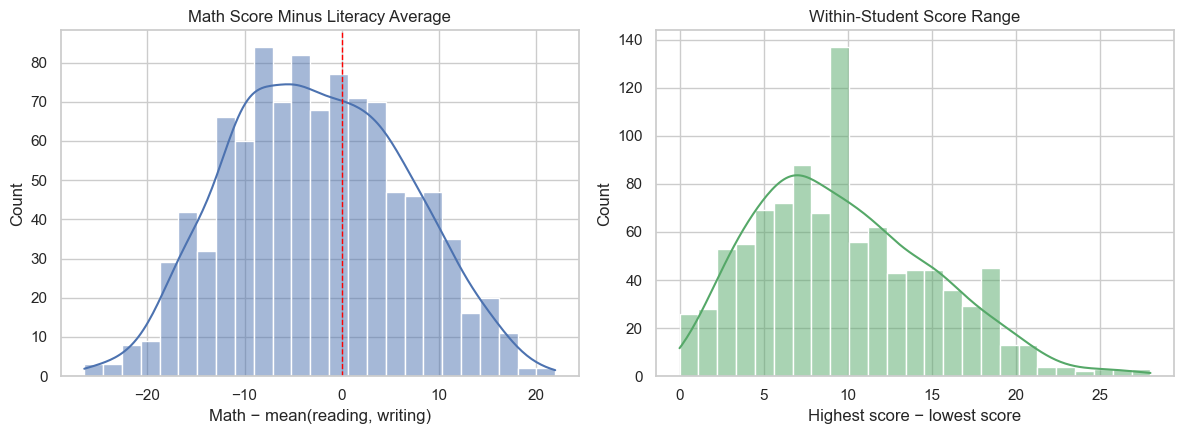

In [22]:
display(df[["overall_average", "literacy_average", "math_minus_literacy", "reading_minus_writing", "within_student_score_range"]].describe().round(2))

gap_by_group = df.groupby("gender", observed=False)[["math_minus_literacy", "reading_minus_writing", "within_student_score_range"]].agg(["mean", "median", "std", "count"])
display(gap_by_group.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=df, x="math_minus_literacy", bins=25, kde=True, color="#4C72B0", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Math Score Minus Literacy Average")
axes[0].set_xlabel("Math − mean(reading, writing)")

sns.histplot(data=df, x="within_student_score_range", bins=25, kde=True, color="#55A868", ax=axes[1])
axes[1].set_title("Within-Student Score Range")
axes[1].set_xlabel("Highest score − lowest score")
plt.tight_layout()
plt.show()

## ۱۵. تحلیل چندمتغیره: آیا می‌توانیم دانش‌آموزها را بر اساس الگوی نمره‌هایشان گروه‌بندی کنیم؟

تا اینجا بیشتر رابطه‌ی دو متغیر یا تفاوت میان گروه‌هایی از پیش تعریف‌شده را بررسی کردیم. در تحلیل چندمتغیره، چند ویژگی را هم‌زمان در نظر می‌گیریم.

در این بخش دو روش را با هم اما با هدف‌های متفاوت استفاده می‌کنیم:

- **K-Means**: دانش‌آموزهایی را که الگوی نمره‌های مشابه دارند، در چند خوشه قرار می‌دهد؛ بدون اینکه از قبل برچسب گروه آن‌ها را بدانیم.
- **PCA**: سه نمره‌ی ریاضی، خواندن و نوشتن را به مؤلفه‌هایی تبدیل می‌کند که خلاصه‌ای از تغییرات داده‌ها را نشان می‌دهند؛ سپس می‌توانیم داده‌ها را در نمودار دوبعدی ببینیم.

برای هر دو روش فقط سه ستون نمره را وارد می‌کنیم. ستون‌هایی مثل جنسیت، ناهار و دوره‌ی آمادگی، دسته‌ای هستند و مستقیماً به مدل عددی نمی‌دهیم؛ بعد از خوشه‌بندی می‌توانیم بررسی کنیم هر خوشه چه ترکیبی از این ویژگی‌ها دارد.



,k,inertia,silhouette_score
0,2,1253.857,0.474
1,3,788.366,0.406
2,4,604.908,0.353
3,5,492.951,0.334
4,6,431.307,0.300


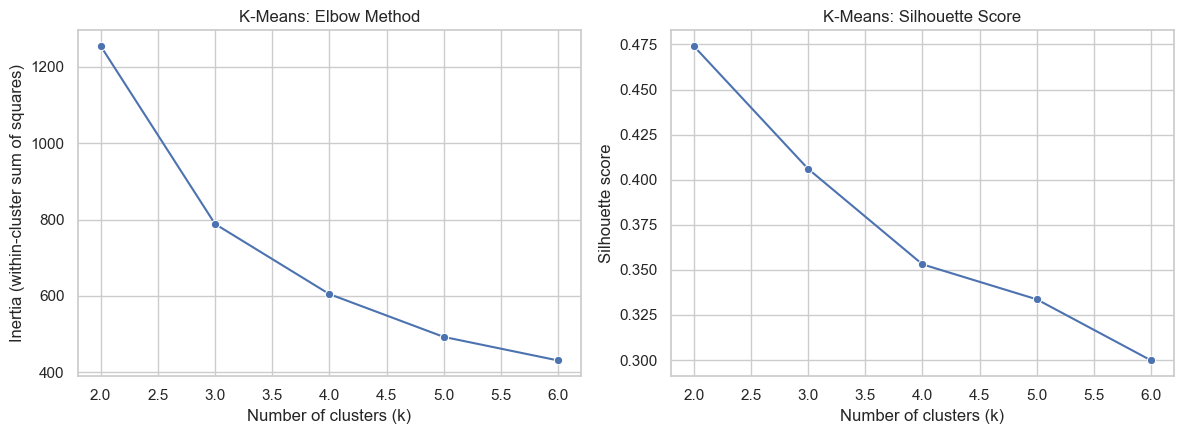

In [23]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Use only the three exam scores as clustering/PCA features.
X_scores = df[score_columns].astype(float).copy()

# Standardize features so each score is measured on a comparable scale.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_scores)

# Compare several candidate numbers of clusters.
k_results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(X_scaled, labels),
    })

k_metrics = pd.DataFrame(k_results)
display(k_metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.lineplot(data=k_metrics, x="k", y="inertia", marker="o", ax=axes[0])
axes[0].set_title("K-Means: Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

sns.lineplot(data=k_metrics, x="k", y="silhouette_score", marker="o", ax=axes[1])
axes[1].set_title("K-Means: Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()


### چطور تعداد خوشه‌ها را انتخاب کنیم؟

در جدول، دو معیار را می‌بینیم:

- **Inertia**: مجموع فاصله‌های مربعی نقاط تا مرکز خوشه‌ی خودشان است. معمولاً با زیادشدن تعداد خوشه‌ها کم می‌شود؛ پس به‌تنهایی نمی‌گوید بهترین `k` چیست. دنبال جایی می‌گردیم که کاهش آن کم‌شتاب‌تر شود؛ به این ایده «روش آرنج» می‌گویند.
- **Silhouette score**: میزان جداشدن خوشه‌ها از یکدیگر را به‌طور تقریبی ارزیابی می‌کند. مقدار نزدیک‌تر به ۱ معمولاً جدایی روشن‌تری را نشان می‌دهد؛ نزدیک صفر یعنی خوشه‌ها هم‌پوشانی دارند و مقدار منفی می‌تواند نشانه‌ی تخصیص نامناسب بعضی نقاط باشد.

در همین دیتاست، بین `k=2` تا `k=6` معمولاً امتیاز Silhouette برای `k=2` از بقیه بالاتر است (حدود **۰٫۴۷**). بااین‌حال، برای روایت آموزشی، در ادامه `k=3` را هم بررسی می‌کنیم تا ببینیم آیا می‌توان سه سطح کلیِ عملکرد پایین‌تر، میانی و بالاتر را تفسیر کرد. بنابراین `k=3` را بهترین انتخاب قطعی معرفی نمی‌کنیم؛ انتخاب `k` به هدف تحلیل و میزان تفسیرپذیری هم وابسته است.


,student_count,share_percent,math score,reading score,writing score,overall_average
kmeans_cluster,,,,,,
Lower-score cluster,249,24.9,48.10,50.67,48.49,49.08
Middle-score cluster,443,44.3,65.34,68.46,67.82,67.21
Higher-score cluster,308,30.8,81.71,85.15,84.21,83.69


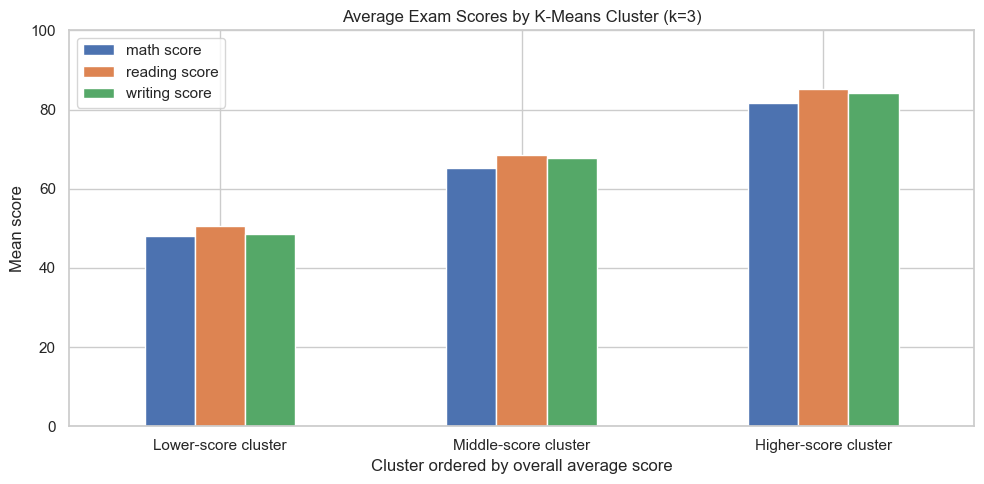

In [24]:
# Use k=3 for an interpretable three-group exploration.
chosen_k = 3
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=20)
df["kmeans_cluster_id"] = kmeans.fit_predict(X_scaled)

# Cluster IDs (0, 1, 2) are arbitrary. Order them by average score for easier reading.
cluster_average = df.groupby("kmeans_cluster_id")["overall_average"].mean().sort_values()
cluster_label_order = ["Lower-score cluster", "Middle-score cluster", "Higher-score cluster"]
cluster_label_map = {
    cluster_id: label
    for cluster_id, label in zip(cluster_average.index, cluster_label_order)
}
df["kmeans_cluster"] = df["kmeans_cluster_id"].map(cluster_label_map)

cluster_counts = df["kmeans_cluster"].value_counts().reindex(cluster_label_order)
cluster_profile = df.groupby("kmeans_cluster")[score_columns + ["overall_average"]].mean().reindex(cluster_label_order)
cluster_profile.insert(0, "student_count", cluster_counts)
cluster_profile.insert(1, "share_percent", (cluster_counts / len(df) * 100).round(1))

display(cluster_profile.round(2))

ax = cluster_profile[score_columns].plot(kind="bar", figsize=(10, 5))
ax.set_title("Average Exam Scores by K-Means Cluster (k=3)")
ax.set_xlabel("Cluster ordered by overall average score")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### تفسیر خوشه‌ها

جدول بالا نشان می‌دهد هر خوشه چند دانش‌آموز دارد و میانگین نمره‌ی هر درس در آن چقدر است. برچسب‌های «پایین‌تر»، «میانی» و «بالاتر» را **بعد از دیدن میانگین کل خوشه‌ها** تعیین کرده‌ایم؛ خود K-Means چنین معنایی برای شماره‌های خوشه قائل نیست.

به‌جای اینکه فقط بگوییم الگوریتم سه خوشه ساخته، بهتر است سؤال کنیم: آیا میانگین سه درس در هر خوشه متفاوت است؟ آیا یک خوشه در ریاضی قوی‌تر و در خواندن/نوشتن ضعیف‌تر است؟ آیا خوشه‌ها از نظر اندازه خیلی نامتوازن‌اند؟ این‌ها تفسیرهای مفیدتر از صرفاً اعلام شماره‌ی خوشه‌اند.

در مرحله‌ی بعد ویژگی‌های دسته‌ای را فقط برای **توصیف پس از خوشه‌بندی** بررسی می‌کنیم؛ این ویژگی‌ها در ساخت خوشه‌ها دخالت داده نشده‌اند.


In [25]:
# Row percentages: within each score-based cluster, how are students split by preparation status?
prep_by_cluster = pd.crosstab(
    df["kmeans_cluster"],
    df["test preparation course"],
    normalize="index"
).mul(100).reindex(cluster_label_order).round(1)

gender_by_cluster = pd.crosstab(
    df["kmeans_cluster"],
    df["gender"],
    normalize="index"
).mul(100).reindex(cluster_label_order).round(1)

display(Markdown("**Test preparation course within each score cluster (%)**"))
display(prep_by_cluster)
display(Markdown("**Gender composition within each score cluster (%)**"))
display(gender_by_cluster)


**Test preparation course within each score cluster (%)**

test preparation course,completed,none
kmeans_cluster,,
Lower-score cluster,20.5,79.5
Middle-score cluster,34.8,65.2
Higher-score cluster,49.7,50.3


**Gender composition within each score cluster (%)**

gender,female,male
kmeans_cluster,,
Lower-score cluster,41.8,58.2
Middle-score cluster,52.4,47.6
Higher-score cluster,59.1,40.9


این جدول‌ها درصدهای درون هر خوشه را نشان می‌دهند؛ برای مثال، در هر سطر درصد افرادی را می‌بینیم که دوره‌ی آمادگی را تمام کرده‌اند یا نکرده‌اند. این تحلیل توصیفی است: اگر ترکیب خوشه‌ها متفاوت باشد، به‌تنهایی ثابت نمی‌کند دوره‌ی آمادگی یا جنسیت علت تفاوت نمرات بوده است. همچنین چون خوشه‌ها فقط با نمرات ساخته شده‌اند، نباید نتیجه را به شکل یک رابطه‌ی علّی تفسیر کرد.

---

## ۱۶. تحلیل مؤلفه‌های اصلی (PCA): سه نمره را چطور در دو محور خلاصه کنیم؟

PCA ویژگی‌های اولیه را حذف یا انتخاب نمی‌کند؛ بلکه از ترکیب خطی آن‌ها **مؤلفه‌های جدید** می‌سازد. مؤلفه‌ی اول بیشترین میزان تغییرات داده‌ها را توضیح می‌دهد، مؤلفه‌ی دوم بیشترین تغییرات باقی‌مانده را توضیح می‌دهد و با مؤلفه‌ی اول هم‌بسته‌ی خطی نیست، و به همین ترتیب ادامه پیدا می‌کند.

در اینجا سه نمره داریم. اگر دو مؤلفه‌ی اول بخش بزرگی از تغییرات را توضیح دهند، می‌توانیم تقریباً کل الگوی سه‌بعدی نمرات را در یک نمودار دوبعدی نمایش دهیم.

از همان داده‌های استانداردشده استفاده می‌کنیم تا اختلاف مقیاس یا واریانس اولیه‌ی هر نمره باعث سلطه‌ی ناخواسته‌ی یک ستون نشود.


**How much variation does each principal component explain?**

,explained_variance_ratio,explained_percent,cumulative_percent
PC1,0.91,90.61,90.61
PC2,0.08,7.89,98.50
PC3,0.01,1.50,100.00


**PCA component loadings**

,PC1,PC2,PC3
math score,0.555,0.831,-0.039
reading score,0.590,-0.359,0.723
writing score,0.587,-0.424,-0.690


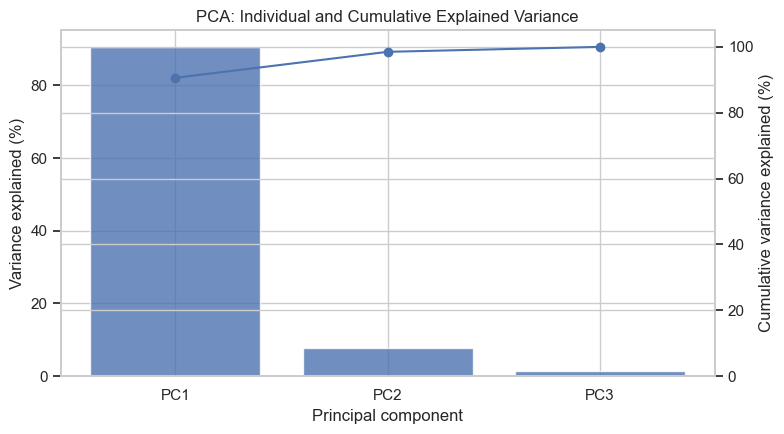

In [26]:
# Fit PCA on all three standardized score variables.
pca = PCA(n_components=len(score_columns))
X_pca = pca.fit_transform(X_scaled)

pc_names = [f"PC{i}" for i in range(1, len(score_columns) + 1)]
pca_variance = pd.DataFrame({
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "explained_percent": pca.explained_variance_ratio_ * 100,
    "cumulative_percent": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=pc_names)

display(Markdown("**How much variation does each principal component explain?**"))
display(pca_variance.round(2))

# Component coefficients show how the original standardized scores contribute to each PC.
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=score_columns,
    columns=pc_names,
)
display(Markdown("**PCA component loadings**"))
display(pca_loadings.round(3))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
component_positions = np.arange(1, len(pc_names) + 1)
ax1.bar(component_positions, pca.explained_variance_ratio_ * 100, alpha=0.8)
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax1.set_xticks(component_positions, pc_names)
ax1.set_title("PCA: Individual and Cumulative Explained Variance")

ax2 = ax1.twinx()
ax2.plot(component_positions, np.cumsum(pca.explained_variance_ratio_) * 100, marker="o")
ax2.set_ylabel("Cumulative variance explained (%)")
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()


### تفسیر نتیجه‌ی PCA

در این دیتاست، اجرای PCA روی سه نمره‌ی استانداردشده نشان می‌دهد که:

- **PC1 حدود ۹۰٫۶٪** از تغییرات را توضیح می‌دهد.
- **PC2 حدود ۷٫۹٪** دیگر را توضیح می‌دهد.
- دو مؤلفه‌ی اول روی‌هم حدود **۹۸٫۵٪** از تغییرات را پوشش می‌دهند.

این نتیجه با همبستگی بالای نمرات سازگار است: دانش‌آموزهایی که در یک درس نمره‌ی بالاتری دارند، غالباً در درس‌های دیگر هم نمره‌ی بالاتری می‌گیرند. بنابراین، بخش زیادی از تفاوت نمرات را می‌توان با یک محور کلی عملکرد خلاصه کرد.

در جدول loadings، ضرایب هر نمره در ساخت هر مؤلفه را می‌بینیم. در داده‌ی حاضر، ضرایب PC1 برای هر سه درس مثبت و نزدیک به هم‌اند؛ پس می‌توان آن را تقریباً محور **عملکرد کلی در آزمون‌ها** تفسیر کرد. در PC2، ریاضی در یک جهت و خواندن/نوشتن در جهت دیگر وزن می‌گیرند؛ بنابراین این مؤلفه بیشتر به **تفاوت نسبی ریاضی با مهارت‌های خواندن و نوشتن** مربوط است.

علامت مثبت یا منفی کل یک مؤلفه قراردادی است: ممکن است نرم‌افزار همه‌ی ضرایب یک مؤلفه را با علامت برعکس نمایش دهد، بی‌آنکه معنای هندسی یا درصد واریانس توضیح‌داده‌شده تغییر کند.


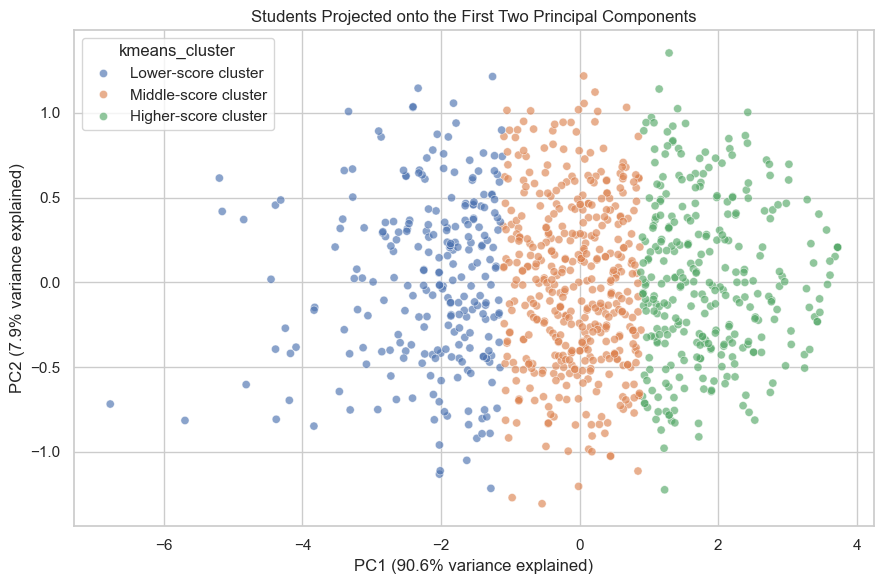

In [27]:
# Plot each student in the first two PCA dimensions and color points by the K-Means clusters.
pca_plot = pd.DataFrame(X_pca[:, :2], columns=["PC1", "PC2"], index=df.index)
pca_plot["kmeans_cluster"] = df["kmeans_cluster"].to_numpy()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="kmeans_cluster",
    hue_order=cluster_label_order,
    alpha=0.65,
    s=35,
)
plt.title("Students Projected onto the First Two Principal Components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance explained)")
plt.tight_layout()
plt.show()


### نمودار نهایی را چطور بخوانیم؟

هر نقطه یک دانش‌آموز است. فاصله‌ی نقاط در این تصویر بر اساس نمرات اصلی پس از استانداردسازی و تبدیل PCA نمایش داده شده؛ رنگ‌ها، خوشه‌هایی را نشان می‌دهند که K-Means پیش‌تر ساخته است.

اگر رنگ‌ها تا حدی از هم جدا باشند، یعنی گروه‌های نمره‌ای در این تصویر دوبعدی هم تفاوت دارند. هم‌پوشانی هم طبیعی است؛ الگوریتم K-Means در فضای سه‌بعدی کار کرده، اما نمودار فقط دو مؤلفه را نمایش می‌دهد، بنابراین تمام اطلاعات را نمی‌بینیم.

### محدودیت‌هایی که در گزارش نهایی باید ذکر شوند

1. K-Means به مقیاس ویژگی‌ها و مقدار `k` حساس است؛ نتیجه‌ی `k=3` فقط یک انتخاب اکتشافی و قابل‌تفسیر است، نه تنها جواب ممکن.
2. خوشه‌ها علت تفاوت نمرات را توضیح نمی‌دهند و گروه‌های رسمی دانش‌آموزان نیستند.
3. PCA برای کاهش ابعاد و خلاصه‌سازی الگوهاست؛ PC1 را نباید یک نمره‌ی رسمی یا متغیر مستقل واقعی دانست.
4. چون فقط سه نمره داشتیم، PCA اینجا بیش از هر چیز به خلاصه‌سازی و تصویرسازی کمک می‌کند. دو مؤلفه‌ی اول حدود ۹۸٫۵٪ تغییرات را حفظ می‌کنند، ولی این به معنی حذف نیاز به تحلیل جداگانه‌ی هر درس نیست.
